# One-to-one binding with mass transport limitation: single-cycle kinetics (SCK)

Parameter-recovery benchmark. This notebook is AI generated.

The data are simulated from the rate equations written below, integrated with SciPy (`solve_ivp`, Radau). No pykingenie function is used to make the data. The data are then fitted with pykingenie, using one Smax (Rmax) shared by all curves, and the fitted parameters are compared with the true ones. A parameter counts as recovered when its relative error is at most 5%.

Gaussian noise with a standard deviation of 0.5 RU is added, 1% of Rmax (50 RU). This is at the high end of real instruments: reference-subtracted SPR data typically show 0.1-0.5 RU of noise, and BLI 0.3-1% of a typical binding signal.


## Model

Two-compartment model: the analyte reaches the surface through a thin layer whose concentration is $C_s$. The flux into the layer is $k_{tr}\,(C - C_s)$, in RU/s, and the layer holds $h$ RU per µM:

$$\frac{dR}{dt} = k_{on}\,C_s\,(R_{max} - R) - k_{off}\,R$$

$$h\,\frac{dC_s}{dt} = k_{tr}\,(C - C_s) - \frac{dR}{dt}, \qquad \text{signal} = R$$

With $h = 0.5$ RU/µM the layer relaxes in about 10 ms. pykingenie fits the quasi-steady-state form of this model ($dC_s/dt = 0$), so the benchmark also checks that this approximation is accurate. Here $k_{on} R_{max} / k_{tr} = 1$: binding is strongly limited by transport.

pykingenie reports `Kd [µM]`, `k_off [1/s]`, `Ktr` (= $k_{tr}$, in RU/(µM·s)) and `Smax`.

In [1]:
import sys

import numpy as np

sys.path.insert(0, '..')
from benchmark_helpers import simulate_sck, compare_parameters, plot_fit
from pykingenie.fitter_surface import KineticsFitter

## True parameters and experiment design

The concentrations are injected one after the other without regeneration: 120 s of injection and 60 s of buffer each, and 900 s of buffer after the last injection. Sampling every 1 s.

In [2]:
params = dict(kon=1.0, koff=0.01, Rmax=50.0, ktr=50.0, h=0.5)  # ktr in RU/(µM·s), h in RU/µM
concs = [0.0011, 0.0033, 0.01, 0.03, 0.09]  # µM, Kd = 0.01 µM

true_values = {'Kd': params['koff'] / params['kon'], 'k_off': params['koff'], 'k_tr': params['ktr'], 'Smax': params['Rmax']}

## Rate equations (first principles)

In [3]:
def rhs(t, y, conc, p):
    R, Cs = y
    dR = p['kon'] * Cs * (p['Rmax'] - R) - p['koff'] * R
    dCs = (p['ktr'] * (conc - Cs) - dR) / p['h']
    return [dR, dCs]


def signal(y, p):
    return y[:, 0]


y0 = [0.0, 0.0]  # no bound analyte, buffer in the layer

## Simulate the data

In [4]:
data = simulate_sck(rhs, signal, y0, params, concs, assoc_time=120.0, disso_time=60.0, final_disso_time=900.0, dt=1.0,
                    noise_sd=0.5, seed=0)

## Fit with pykingenie

One Smax shared by all curves (`smax_id` is 0 for every curve).

In [5]:
fitter = KineticsFitter(
    time_assoc_lst=data['time_assoc'], association_signal_lst=data['assoc'],
    lig_conc_lst=concs,
    time_diss_lst=data['time_disso'], dissociation_signal_lst=data['disso'],
    smax_id=[0] * len(concs), name_lst=['benchmark'], is_single_cycle=True,
)
fitter.get_steady_state()
fitter.fit_one_site_assoc_and_disso(shared_smax=True, fit_ktr=True)
fitter.fit_params_kinetics

,Kd [µM],k_off [1/s],Smax,(Derived) k_on [1/µM/s],Ktr
0,0.009998,0.010189,49.982863,1.019033,48.326908


## Compare with the true parameters

In [6]:
fitted_values = {'Kd': fitter.Kd, 'k_off': fitter.k_off,
                 'k_tr': fitter.fit_params_kinetics['Ktr'].iloc[0], 'Smax': fitter.Smax[0]}

comparison = compare_parameters(true_values, fitted_values, rtol=0.05)
worst = comparison['rel. error (%)'].abs().idxmax()
print(f"All parameters recovered within 5%: {comparison['recovered'].all()}. "
      f"Largest error: {comparison.loc[worst, 'rel. error (%)']:+.2f}% ({worst})")
comparison

All parameters recovered within 5%: True. Largest error: -3.35% (k_tr)


,true,fitted,rel. error (%),recovered
parameter,,,,
Kd,0.01,0.009998,-0.015952,True
k_off,0.01,0.010189,1.886997,True
k_tr,50.00,48.326908,-3.346184,True
Smax,50.00,49.982863,-0.034275,True


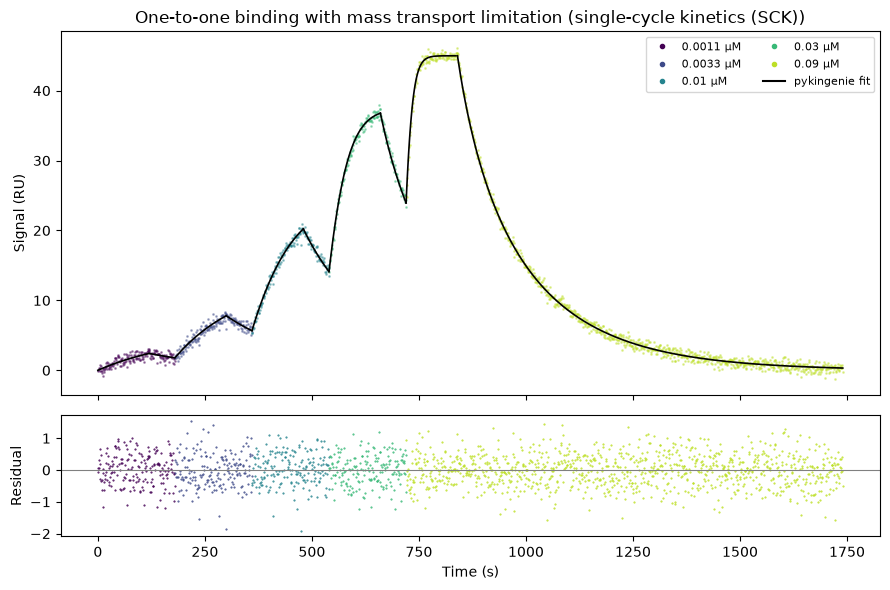

In [7]:
fig = plot_fit(data, fitter, concs, 'One-to-one binding with mass transport limitation (single-cycle kinetics (SCK))')